--- ROOMS KPI RESULTS ---
       Hotel  Available Room Nights  Room Nights Sold  Occupancy %  ADR (€)  RevPAR (€)  Room Revenue (€)
  City Hotel                  21900             14414         65.8    113.5        74.3        1627958.18
Resort Hotel                  24090             16263         67.5    132.8        89.4        2152935.55




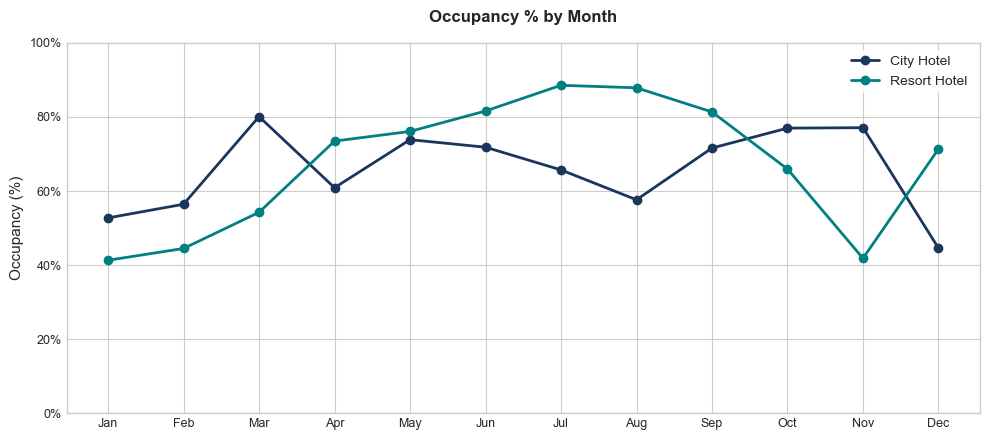

Step 1 & 2 completed successfully! Chart saved as 'Occupancy_by_Month.png'.


In [6]:
# =============================================================================
# STEP 1 & STEP 2: Environment Setup, Stay-Night Expansion & Rooms KPIs
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and chart styles
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10

# 1. Load dataset and expand stays to nights
file_path = r"C:\Users\ngosa\Desktop\GITHUB ROADMAP\synthetic hotel dataset\Hotel_Dataset_2025.csv"
df = pd.read_csv(file_path, parse_dates=["Date", "Booking Date", "Departure Date"])
stays = df[df["Cancellation Status"] == "Not Cancelled"].copy()

nights = stays.loc[stays.index.repeat(stays["LOS"])].copy()
nights["Night"] = nights["Date"] + pd.to_timedelta(nights.groupby(level=0).cumcount(), unit="D")
nights = nights[nights["Night"] <= "2025-12-31"]

# Spread revenue evenly across stay nights
revenue_cols = ["Room Revenue", "Restaurant Revenue", "Bar Revenue", "Spa Revenue", "Meeting/Event Revenue", "Other Revenue"]
for col in revenue_cols:
    nights[col] = nights[col] / nights["LOS"]

nights["Paid"] = (nights["ADR"] > 0).astype(int)
nights["Month_Name"] = nights["Night"].dt.strftime('%b')
nights["Month_Num"] = nights["Night"].dt.month

# 2. Calculate Rooms KPIs
ROOMS = {"City Hotel": 60, "Resort Hotel": 66}

def calc_rooms_kpis(hotel_name):
    n_subset = nights[nights["Hotel"] == hotel_name]
    available_rooms = ROOMS[hotel_name] * 365
    sold_rooms = len(n_subset)
    room_rev = n_subset["Room Revenue"].sum()
    paid_nights = n_subset["Paid"].sum()
    
    occupancy = (sold_rooms / available_rooms) * 100
    adr = room_rev / paid_nights if paid_nights > 0 else 0
    revpar = room_rev / available_rooms
    
    return {
        "Hotel": hotel_name,
        "Available Room Nights": available_rooms,
        "Room Nights Sold": sold_rooms,
        "Occupancy %": round(occupancy, 1),
        "ADR (€)": round(adr, 1),
        "RevPAR (€)": round(revpar, 1),
        "Room Revenue (€)": round(room_rev, 2)
    }

rooms_kpi_results = pd.DataFrame([calc_rooms_kpis("City Hotel"), calc_rooms_kpis("Resort Hotel")])
print("--- ROOMS KPI RESULTS ---")
print(rooms_kpi_results.to_string(index=False))
print("\n")

# 3. Generate Monthly Occupancy Chart
COLOR_CITY = '#1b365d'
COLOR_RESORT = '#008080'
days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

monthly_occ = nights.groupby(["Month_Num", "Month_Name", "Hotel"]).size().reset_index(name="SoldNights")
monthly_occ_pivot = monthly_occ.pivot_table(index=["Month_Num", "Month_Name"], columns="Hotel", values="SoldNights").reset_index()

for hotel in ["City Hotel", "Resort Hotel"]:
    monthly_occ_pivot[f"{hotel}_Occ"] = monthly_occ_pivot.apply(
        lambda row: (row[hotel] / (ROOMS[hotel] * days_in_month[int(row["Month_Num"]) - 1])) * 100, axis=1
    )

plt.figure(figsize=(10, 4.5))
plt.plot(monthly_occ_pivot["Month_Name"], monthly_occ_pivot["City Hotel_Occ"], marker='o', color=COLOR_CITY, linewidth=2, label="City Hotel")
plt.plot(monthly_occ_pivot["Month_Name"], monthly_occ_pivot["Resort Hotel_Occ"], marker='o', color=COLOR_RESORT, linewidth=2, label="Resort Hotel")

plt.title("Occupancy % by Month", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("Occupancy (%)")
plt.ylim(0, 100)
plt.gca().yaxis.set_major_formatter('{x:.0f}%')
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()

plt.savefig("Occupancy_by_Month.png", dpi=300)
plt.show()

print("Step 1 & 2 completed successfully! Chart saved as 'Occupancy_by_Month.png'.")

--- ROOM TYPE PERFORMANCE RESULTS ---
       Hotel          Room Type  Occupancy %  ADR (€)  RevPAR (€)
  City Hotel      Standard Room         63.5     87.6        55.3
  City Hotel      Superior Room         78.9    111.0        87.1
  City Hotel        Deluxe Room         69.7    132.7        92.2
  City Hotel       Junior Suite         49.1    171.1        83.3
  City Hotel              Suite         40.8    239.6        97.8
Resort Hotel      Standard Room         65.3    100.2        65.2
Resort Hotel Deluxe Garden View         70.5    128.4        90.3
Resort Hotel   Deluxe Pool View         65.0    151.9        98.5
Resort Hotel        Family Room         71.8    160.0       114.8
Resort Hotel              Villa         63.6    310.9       197.2




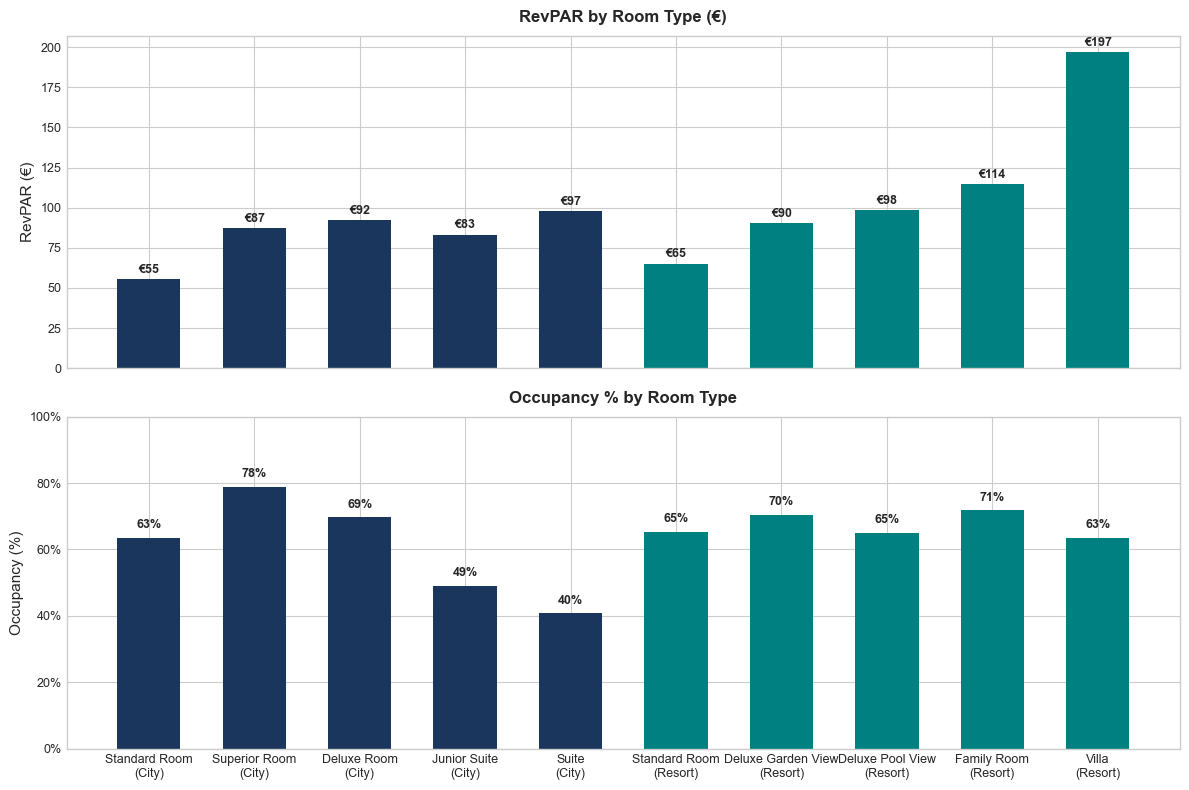

Step 3 Complete: Room Type performance analyzed and chart saved as 'Room_Type_Performance.png'


In [7]:
# =============================================================================
# STEP 3: Room Type Performance Analysis & Charts
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define inventory mapping for each room type per hotel
room_inventory = {
    ("City Hotel", "Standard Room"): 26,
    ("City Hotel", "Superior Room"): 15,
    ("City Hotel", "Deluxe Room"): 10,
    ("City Hotel", "Junior Suite"): 6,
    ("City Hotel", "Suite"): 3,
    ("Resort Hotel", "Standard Room"): 24,
    ("Resort Hotel", "Deluxe Garden View"): 18,
    ("Resort Hotel", "Deluxe Pool View"): 13,
    ("Resort Hotel", "Family Room"): 9,
    ("Resort Hotel", "Villa"): 2
}

room_type_stats = []
for (hotel, rtype), inv in room_inventory.items():
    subset = nights[(nights["Hotel"] == hotel) & (nights["Room Type"] == rtype)]
    avail_nights = inv * 365
    sold_nights = len(subset)
    room_rev = subset["Room Revenue"].sum()
    paid_nights = subset["Paid"].sum()
    
    occ = (sold_nights / avail_nights) * 100
    adr = room_rev / paid_nights if paid_nights > 0 else 0
    revpar = room_rev / avail_nights
    
    room_type_stats.append({
        "Hotel": hotel,
        "Room Type": rtype,
        "Occupancy %": round(occ, 1),
        "ADR (€)": round(adr, 1),
        "RevPAR (€)": round(revpar, 1)
    })

rt_df = pd.DataFrame(room_type_stats)
print("--- ROOM TYPE PERFORMANCE RESULTS ---")
print(rt_df.to_string(index=False))
print("\n")

# --- VISUALIZATION: RevPAR and Occupancy by Room Type ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Colors for bars (City Hotel = Navy, Resort Hotel = Teal)
bar_colors = [COLOR_CITY if h == "City Hotel" else COLOR_RESORT for h in rt_df["Hotel"]]
x_labels = [f"{row['Room Type']}\n({row['Hotel'].split()[0]})" for _, row in rt_df.iterrows()]

# 1. RevPAR by Room Type
axes[0].bar(x_labels, rt_df["RevPAR (€)"], color=bar_colors, width=0.6)
axes[0].set_title("RevPAR by Room Type (€)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("RevPAR (€)")
for i, v in enumerate(rt_df["RevPAR (€)"]):
    axes[0].text(i, v + 2, f"€{int(v)}", ha='center', va='bottom', fontsize=9, fontweight='bold')

# 2. Occupancy % by Room Type
axes[1].bar(x_labels, rt_df["Occupancy %"], color=bar_colors, width=0.6)
axes[1].set_title("Occupancy % by Room Type", fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel("Occupancy (%)")
axes[1].set_ylim(0, 100)
axes[1].yaxis.set_major_formatter('{x:.0f}%')
for i, v in enumerate(rt_df["Occupancy %"]):
    axes[1].text(i, v + 2, f"{int(v)}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.xticks(rotation=0, ha='center')
plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Room_Type_Performance.png", dpi=300)
plt.show()

print("Step 3 Complete: Room Type performance analyzed and chart saved as 'Room_Type_Performance.png'")

--- BOOKING PACE SUMMARY (% OF ROOM NIGHTS ON THE BOOKS) ---
Hotel  City Hotel  Resort Hotel
Days                           
180           5.8          10.7
150           8.3          14.5
120          12.5          20.5
90           18.7          32.3
60           30.2          48.2
45           38.0          57.0
30           48.3          68.8
21           55.6          77.3
14           64.4          84.1
7            78.2          91.2
3            88.8          94.7
0           100.0         100.0




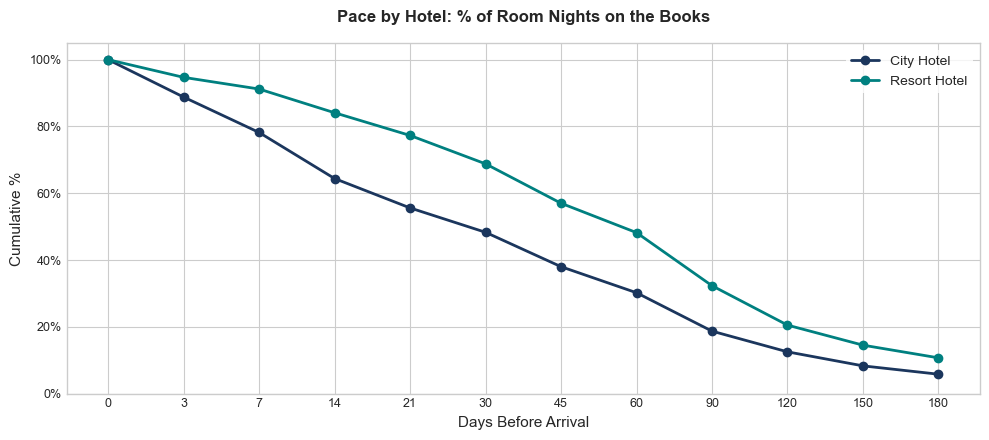

Step 4 Complete: Booking pace calculated and chart saved as 'Booking_Pace.png'


In [8]:
# =============================================================================
# STEP 4: Booking Pace Analysis & Chart
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt

# Define lead time windows (days before arrival)
lead_time_bins = [180, 150, 120, 90, 60, 45, 30, 21, 14, 7, 3, 0]
pace_data = []

for days in lead_time_bins:
    for hotel in ["City Hotel", "Resort Hotel"]:
        h_subset = stays[stays["Hotel"] == hotel]
        cum_nights = h_subset.loc[h_subset["Lead Time"] >= days, "LOS"].sum()
        total_nights = h_subset["LOS"].sum()
        pace_data.append({
            "Days": days, 
            "Hotel": hotel, 
            "Pace %": round((cum_nights / total_nights) * 100, 1)
        })

pace_df = pd.DataFrame(pace_data)
pace_pivot = pace_df.pivot(index="Days", columns="Hotel", values="Pace %").sort_index(ascending=False)

print("--- BOOKING PACE SUMMARY (% OF ROOM NIGHTS ON THE BOOKS) ---")
print(pace_pivot)
print("\n")

# --- VISUALIZATION: Booking Pace Curves ---
plt.figure(figsize=(10, 4.5))
plt.plot(pace_pivot.index.astype(str), pace_pivot["City Hotel"], marker='o', color=COLOR_CITY, linewidth=2, label="City Hotel")
plt.plot(pace_pivot.index.astype(str), pace_pivot["Resort Hotel"], marker='o', color=COLOR_RESORT, linewidth=2, label="Resort Hotel")

plt.title("Pace by Hotel: % of Room Nights on the Books", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Days Before Arrival")
plt.ylabel("Cumulative %")
plt.gca().invert_xaxis()  # Invert x-axis so 180 days out is on the left and 0 is on the right
plt.ylim(0, 105)
plt.gca().yaxis.set_major_formatter('{x:.0f}%')
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Booking_Pace.png", dpi=300)
plt.show()

print("Step 4 Complete: Booking pace calculated and chart saved as 'Booking_Pace.png'")

--- PICKUP SUMMARY (% OF ROOM NIGHTS BY BOOKING WINDOW) ---
Hotel      City Hotel  Resort Hotel
Window                             
0 to 7           24.2           9.7
8 to 14          12.9           7.1
15 to 30         15.6          15.1
31 to 60         17.6          20.9
61 to 90         11.3          15.3
91 to 180        12.8          21.3
181+              5.7          10.6




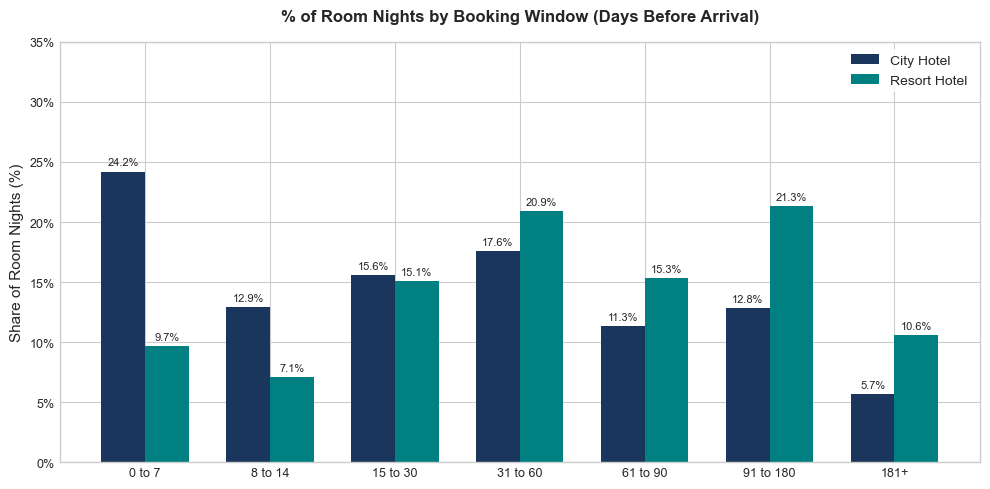

Step 5 Complete: Pickup analysis completed and chart saved as 'Pickup_Windows.png'


In [9]:
# =============================================================================
# STEP 5: Pickup Analysis (Booking Windows) & Chart
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define booking windows
def get_window(lead_time):
    if lead_time <= 7: return "0 to 7"
    elif lead_time <= 14: return "8 to 14"
    elif lead_time <= 30: return "15 to 30"
    elif lead_time <= 60: return "31 to 60"
    elif lead_time <= 90: return "61 to 90"
    elif lead_time <= 180: return "91 to 180"
    else: return "181+"

stays["Window"] = stays["Lead Time"].apply(get_window)
window_order = ["0 to 7", "8 to 14", "15 to 30", "31 to 60", "61 to 90", "91 to 180", "181+"]

pickup_data = []
for hotel in ["City Hotel", "Resort Hotel"]:
    h_subset = stays[stays["Hotel"] == hotel]
    total_nights = h_subset["LOS"].sum()
    for w in window_order:
        w_nights = h_subset.loc[h_subset["Window"] == w, "LOS"].sum()
        pct = (w_nights / total_nights) * 100
        pickup_data.append({"Hotel": hotel, "Window": w, "Pickup %": round(pct, 1)})

pickup_df = pd.DataFrame(pickup_data)
pickup_pivot = pickup_df.pivot(index="Window", columns="Hotel", values="Pickup %").reindex(window_order)

print("--- PICKUP SUMMARY (% OF ROOM NIGHTS BY BOOKING WINDOW) ---")
print(pickup_pivot)
print("\n")

# --- VISUALIZATION: Pickup by Booking Window ---
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(window_order))
width = 0.35

rects1 = ax.bar(x - width/2, pickup_pivot["City Hotel"], width, label='City Hotel', color=COLOR_CITY)
rects2 = ax.bar(x + width/2, pickup_pivot["Resort Hotel"], width, label='Resort Hotel', color=COLOR_RESORT)

ax.set_title("% of Room Nights by Booking Window (Days Before Arrival)", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Share of Room Nights (%)")
ax.set_xticks(x)
ax.set_xticklabels(window_order)
ax.set_ylim(0, 35)
ax.yaxis.set_major_formatter('{x:.0f}%')
ax.legend(frameon=True, facecolor='white', edgecolor='none')

# Add data labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Pickup_Windows.png", dpi=300)
plt.show()

print("Step 5 Complete: Pickup analysis completed and chart saved as 'Pickup_Windows.png'")

--- MARKET SEGMENT ANALYSIS RESULTS ---
           Segment  Nights Share %  ADR (€)  Cancellation Rate %  Median Lead Time (days)  Ancillary Share %
           Leisure            49.6    137.9                 31.9                       36               36.7
     Tour Operator            17.6     99.8                 31.5                       88               41.0
Business Transient            12.5    130.4                 14.4                        5               19.9
             Group            11.3    100.9                 16.8                       94               47.3
Corporate Contract             8.6    111.6                  9.6                       12               23.8
     Complimentary             0.4      0.0                  0.0                        0                0.0




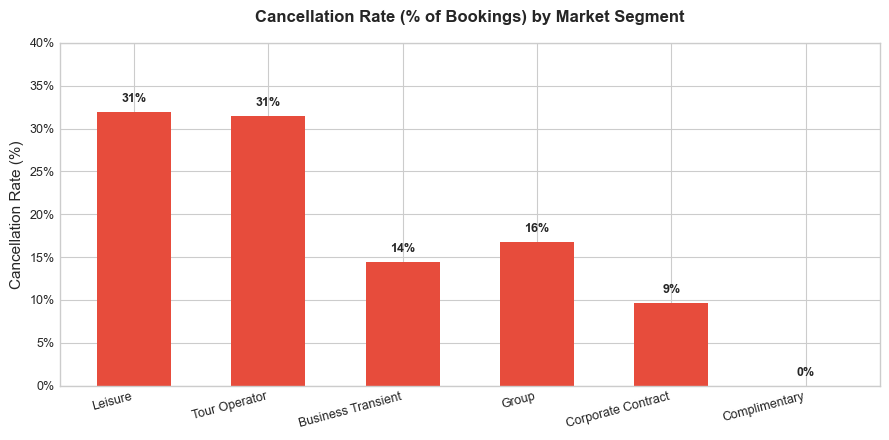

Step 6 Complete: Market segment analysis completed and chart saved as 'Segment_Cancellations.png'


In [10]:
# =============================================================================
# STEP 6: Market Segment Analysis & Chart
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Calculate Market Segment metrics
stays = df[df["Cancellation Status"] == "Not Cancelled"].copy()
total_nights_all = stays["LOS"].sum()

segment_stats = []
for seg, group in df.groupby("Market Segment"):
    stay_group = group[group["Cancellation Status"] == "Not Cancelled"]
    cancel_rate = (group["Cancellation Status"] == "Cancelled").mean() * 100
    nights_share = (stay_group["LOS"].sum() / total_nights_all) * 100
    
    paid_group = stay_group[stay_group["ADR"] > 0]
    adr = paid_group["Room Revenue"].sum() / paid_group["LOS"].sum() if paid_group["LOS"].sum() > 0 else 0
    
    total_rev = (stay_group["Room Revenue"] + stay_group["Restaurant Revenue"] + 
                 stay_group["Bar Revenue"] + stay_group["Spa Revenue"] + 
                 stay_group["Meeting/Event Revenue"] + stay_group["Other Revenue"]).sum()
    room_rev = stay_group["Room Revenue"].sum()
    
    rev_per_room_night = total_rev / stay_group["LOS"].sum() if stay_group["LOS"].sum() > 0 else 0
    median_lead = stay_group["Lead Time"].median()
    ancillary_share = ((total_rev - room_rev) / total_rev) * 100 if total_rev > 0 else 0
    
    segment_stats.append({
        "Segment": seg,
        "Nights Share %": round(nights_share, 1),
        "ADR (€)": round(adr, 1),
        "Cancellation Rate %": round(cancel_rate, 1),
        "Median Lead Time (days)": int(median_lead),
        "Ancillary Share %": round(ancillary_share, 1)
    })

seg_df = pd.DataFrame(segment_stats).sort_values(by="Nights Share %", ascending=False)

print("--- MARKET SEGMENT ANALYSIS RESULTS ---")
print(seg_df.to_string(index=False))
print("\n")

# --- VISUALIZATION: Cancellation Rate by Market Segment ---
plt.figure(figsize=(9, 4.5))
bars = plt.bar(seg_df["Segment"], seg_df["Cancellation Rate %"], color='#e74c3c', width=0.55)

plt.title("Cancellation Rate (% of Bookings) by Market Segment", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 40)
plt.gca().yaxis.set_major_formatter('{x:.0f}%')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.8, f"{int(height)}%", 
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.xticks(rotation=15, ha='right')
plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Segment_Cancellations.png", dpi=300)
plt.show()

print("Step 6 Complete: Market segment analysis completed and chart saved as 'Segment_Cancellations.png'")

--- CHANNEL ANALYSIS RESULTS ---
                   Channel  Nights Share %  ADR (€)  Cancellation Rate %  Median Lead Time (days)  Ancillary Share %
Travel Agent/Tour Operator            25.7    111.1                 28.8                       77               40.4
      Online Travel Agency            22.7    135.7                 37.8                       26               35.6
            Direct Website            19.2    137.6                 21.9                       24               34.3
               Phone/Email            17.3    117.5                 14.2                       58               39.4
Global Distribution System             8.2    115.1                 16.8                       10               27.8
    Corporate Booking Tool             6.5    118.9                 10.1                       10               21.7
                Front Desk             0.4      0.0                  0.0                        0                0.0




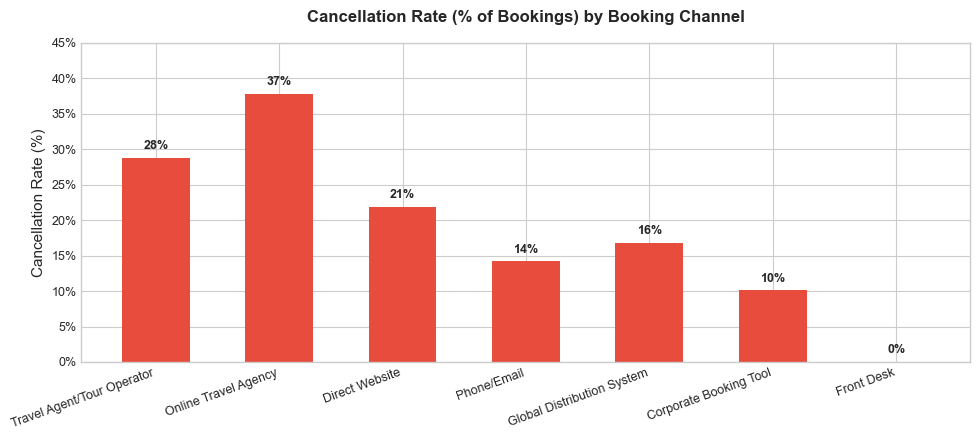

Step 7 Complete: Channel analysis completed and chart saved as 'Channel_Cancellations.png'


In [11]:
# =============================================================================
# STEP 7: Channel Analysis & Chart
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt

# Calculate Booking Channel metrics
stays = df[df["Cancellation Status"] == "Not Cancelled"].copy()
total_nights_all = stays["LOS"].sum()

channel_stats = []
for chan, group in df.groupby("Booking Channel"):
    stay_group = group[group["Cancellation Status"] == "Not Cancelled"]
    cancel_rate = (group["Cancellation Status"] == "Cancelled").mean() * 100
    nights_share = (stay_group["LOS"].sum() / total_nights_all) * 100
    
    paid_group = stay_group[stay_group["ADR"] > 0]
    adr = paid_group["Room Revenue"].sum() / paid_group["LOS"].sum() if paid_group["LOS"].sum() > 0 else 0
    
    total_rev = (stay_group["Room Revenue"] + stay_group["Restaurant Revenue"] + 
                 stay_group["Bar Revenue"] + stay_group["Spa Revenue"] + 
                 stay_group["Meeting/Event Revenue"] + stay_group["Other Revenue"]).sum()
    room_rev = stay_group["Room Revenue"].sum()
    
    median_lead = stay_group["Lead Time"].median()
    ancillary_share = ((total_rev - room_rev) / total_rev) * 100 if total_rev > 0 else 0
    
    channel_stats.append({
        "Channel": chan,
        "Nights Share %": round(nights_share, 1),
        "ADR (€)": round(adr, 1),
        "Cancellation Rate %": round(cancel_rate, 1),
        "Median Lead Time (days)": int(median_lead) if not pd.isna(median_lead) else 0,
        "Ancillary Share %": round(ancillary_share, 1)
    })

chan_df = pd.DataFrame(channel_stats).sort_values(by="Nights Share %", ascending=False)

print("--- CHANNEL ANALYSIS RESULTS ---")
print(chan_df.to_string(index=False))
print("\n")

# --- VISUALIZATION: Cancellation Rate by Booking Channel ---
plt.figure(figsize=(10, 4.5))
bars = plt.bar(chan_df["Channel"], chan_df["Cancellation Rate %"], color='#e74c3c', width=0.55)

plt.title("Cancellation Rate (% of Bookings) by Booking Channel", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 45)
plt.gca().yaxis.set_major_formatter('{x:.0f}%')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.8, f"{int(height)}%", 
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.xticks(rotation=20, ha='right')
plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Channel_Cancellations.png", dpi=300)
plt.show()

print("Step 7 Complete: Channel analysis completed and chart saved as 'Channel_Cancellations.png'")

--- TOTAL HOTEL KPI RESULTS ---
       Hotel  Total Revenue (€)  TRevPAR (€)  GOPPAR (€)  GOP Margin %
  City Hotel         2216405.81        101.2        33.0          32.6
Resort Hotel         3685786.18        153.0        39.3          25.7




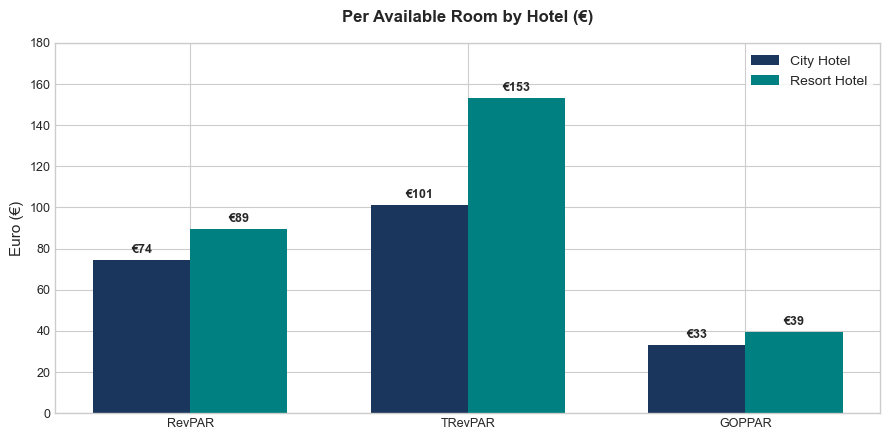

Step 8 Complete: Total hotel KPIs calculated and chart saved as 'Total_Hotel_KPIs.png'


In [12]:
# =============================================================================
# STEP 8: Total Hotel KPIs (TRevPAR & GOPPAR) & Chart
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define illustrative cost assumptions and departmental profit margins
MARGINS = {"Rooms": 0.72, "F&B": 0.30, "Spa": 0.35, "Meetings": 0.45, "Other": 0.50}
UNDISTRIBUTED_RATE = 0.30

def calc_total_kpis(hotel_name):
    n_subset = nights[nights["Hotel"] == hotel_name]
    available_rooms = ROOMS[hotel_name] * 365
    
    rev_rooms = n_subset["Room Revenue"].sum()
    rev_fb = (n_subset["Restaurant Revenue"] + n_subset["Bar Revenue"]).sum()
    rev_spa = n_subset["Spa Revenue"].sum()
    rev_meetings = n_subset["Meeting/Event Revenue"].sum()
    rev_other = n_subset["Other Revenue"].sum()
    
    total_rev = rev_rooms + rev_fb + rev_spa + rev_meetings + rev_other
    
    dept_profits = {
        "Rooms": rev_rooms * MARGINS["Rooms"],
        "F&B": rev_fb * MARGINS["F&B"],
        "Spa": rev_spa * MARGINS["Spa"],
        "Meetings": rev_meetings * MARGINS["Meetings"],
        "Other": rev_other * MARGINS["Other"]
    }
    total_dept_profit = sum(dept_profits.values())
    undistributed_expenses = total_rev * UNDISTRIBUTED_RATE
    gop = total_dept_profit - undistributed_expenses
    
    return {
        "Hotel": hotel_name,
        "Total Revenue (€)": round(total_rev, 2),
        "TRevPAR (€)": round(total_rev / available_rooms, 1),
        "GOPPAR (€)": round(gop / available_rooms, 1),
        "GOP Margin %": round((gop / total_rev) * 100, 1)
    }

total_kpi_results = pd.DataFrame([calc_total_kpis("City Hotel"), calc_total_kpis("Resort Hotel")])
print("--- TOTAL HOTEL KPI RESULTS ---")
print(total_kpi_results.to_string(index=False))
print("\n")

# --- VISUALIZATION: RevPAR, TRevPAR, and GOPPAR by Hotel ---
metrics = ["RevPAR", "TRevPAR", "GOPPAR"]
city_vals = [74.3, 101.2, 33.0]
resort_vals = [89.4, 153.0, 39.3]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))
rects1 = ax.bar(x - width/2, city_vals, width, label='City Hotel', color=COLOR_CITY)
rects2 = ax.bar(x + width/2, resort_vals, width, label='Resort Hotel', color=COLOR_RESORT)

ax.set_title("Per Available Room by Hotel (€)", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Euro (€)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 180)
ax.legend(frameon=True, facecolor='white', edgecolor='none')

def autolabel_euro(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'€{int(height)}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel_euro(rects1)
autolabel_euro(rects2)

plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Total_Hotel_KPIs.png", dpi=300)
plt.show()

print("Step 8 Complete: Total hotel KPIs calculated and chart saved as 'Total_Hotel_KPIs.png'")

--- REVENUE MIX & DEPARTMENTAL PROFIT CONTRIBUTION ---
       Hotel Department  Revenue (€)  Revenue Share %  Dept Profit (€)  Profit Share %
  City Hotel      Rooms   1627958.18             73.5       1172129.89            84.5
  City Hotel        F&B    329137.86             14.9         98741.36             7.1
  City Hotel        Spa     56113.69              2.5         19639.79             1.4
  City Hotel   Meetings    108823.51              4.9         48970.58             3.5
  City Hotel      Other     94372.57              4.3         47186.29             3.4
Resort Hotel      Rooms   2152935.55             58.4       1550113.60            75.5
Resort Hotel        F&B   1164051.86             31.6        349215.56            17.0
Resort Hotel        Spa    184744.00              5.0         64660.40             3.2
Resort Hotel   Meetings     81443.78              2.2         36649.70             1.8
Resort Hotel      Other    102610.99              2.8         51305.49     

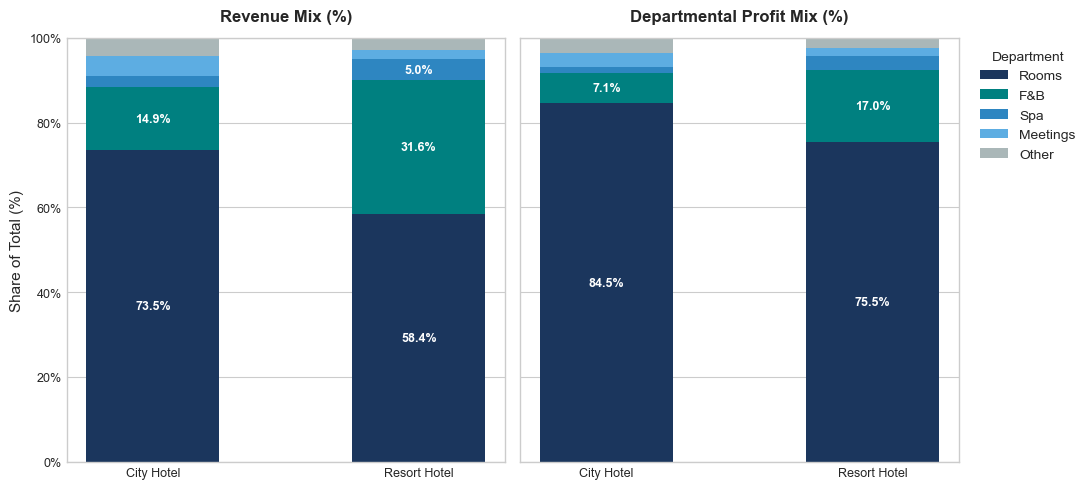

Step 9 Complete: Revenue & Profit Mix analyzed and chart saved as 'Revenue_Profit_Mix.png'


In [13]:
# =============================================================================
# STEP 9: Revenue Mix & Departmental Profit Contribution
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Calculate Revenue Mix and Departmental Profit Share
mix_data = []
for hotel in ["City Hotel", "Resort Hotel"]:
    sub = nights[nights["Hotel"] == hotel]
    rev_rooms = sub["Room Revenue"].sum()
    rev_fb = (sub["Restaurant Revenue"] + sub["Bar Revenue"]).sum()
    rev_spa = sub["Spa Revenue"].sum()
    rev_meetings = sub["Meeting/Event Revenue"].sum()
    rev_other = sub["Other Revenue"].sum()
    total_rev = rev_rooms + rev_fb + rev_spa + rev_meetings + rev_other
    
    prof_rooms = rev_rooms * MARGINS["Rooms"]
    prof_fb = rev_fb * MARGINS["F&B"]
    prof_spa = rev_spa * MARGINS["Spa"]
    prof_meetings = rev_meetings * MARGINS["Meetings"]
    prof_other = rev_other * MARGINS["Other"]
    total_prof = prof_rooms + prof_fb + prof_spa + prof_meetings + prof_other
    
    depts = [
        ("Rooms", rev_rooms, prof_rooms),
        ("F&B", rev_fb, prof_fb),
        ("Spa", rev_spa, prof_spa),
        ("Meetings", rev_meetings, prof_meetings),
        ("Other", rev_other, prof_other)
    ]
    for d_name, d_rev, d_prof in depts:
        mix_data.append({
            "Hotel": hotel,
            "Department": d_name,
            "Revenue (€)": round(d_rev, 2),
            "Revenue Share %": round((d_rev / total_rev) * 100, 1),
            "Dept Profit (€)": round(d_prof, 2),
            "Profit Share %": round((d_prof / total_prof) * 100, 1)
        })

mix_df = pd.DataFrame(mix_data)
print("--- REVENUE MIX & DEPARTMENTAL PROFIT CONTRIBUTION ---")
print(mix_df.to_string(index=False))
print("\n")

# --- VISUALIZATION: Revenue Mix vs. Departmental Profit Mix (100% Stacked Bar) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

dept_order = ["Rooms", "F&B", "Spa", "Meetings", "Other"]
dept_colors = [COLOR_CITY, COLOR_RESORT, '#2e86c1', '#5dade2', '#aab7b8']

for idx, (metric_col, title_label) in enumerate([
    ("Revenue Share %", "Revenue Mix (%)"),
    ("Profit Share %", "Departmental Profit Mix (%)")
]):
    ax = axes[idx]
    piv = mix_df.pivot(index="Hotel", columns="Department", values=metric_col).reindex(["City Hotel", "Resort Hotel"])[dept_order]
    
    bottom = np.zeros(len(piv))
    for d_idx, dept in enumerate(dept_order):
        vals = piv[dept].values
        bars = ax.bar(piv.index, vals, bottom=bottom, label=dept, color=dept_colors[d_idx], width=0.5)
        for bar, val in zip(bars, vals):
            if val >= 5.0:  # Label segments >= 5% for clean readability
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + val / 2, f"{val:.1f}%",
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)
        bottom += vals
        
    ax.set_title(title_label, fontsize=12, fontweight='bold', pad=12)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter('{x:.0f}%')

axes[0].set_ylabel("Share of Total (%)")
axes[1].legend(title="Department", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()

# Save image for GitHub repository and display inline
plt.savefig("Revenue_Profit_Mix.png", dpi=300, bbox_inches='tight')
plt.show()

print("Step 9 Complete: Revenue & Profit Mix analyzed and chart saved as 'Revenue_Profit_Mix.png'")